In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_data_df = pd.read_csv("../data/train.csv")
test_data_df = pd.read_csv("../data/test.csv")

In [3]:
train_data_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
train_data_df['SalePrice'].min()

np.int64(34900)

In [5]:
test_data_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [12]:
print(train_data_df.shape)
print(train_data_df.info())
print(train_data_df.describe())

(1460, 82)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 82 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   Id             1460 non-null   int64   
 1   MSSubClass     1460 non-null   int64   
 2   MSZoning       1460 non-null   str     
 3   LotFrontage    1201 non-null   float64 
 4   LotArea        1460 non-null   int64   
 5   Street         1460 non-null   str     
 6   Alley          91 non-null     str     
 7   LotShape       1460 non-null   str     
 8   LandContour    1460 non-null   str     
 9   Utilities      1460 non-null   str     
 10  LotConfig      1460 non-null   str     
 11  LandSlope      1460 non-null   str     
 12  Neighborhood   1460 non-null   str     
 13  Condition1     1460 non-null   str     
 14  Condition2     1460 non-null   str     
 15  BldgType       1460 non-null   str     
 16  HouseStyle     1460 non-null   str     
 17  OverallQual    1460 non-null   in

Check where there are null values

In [14]:
train_data_df.isnull().sum().sort_values(ascending=False).head(20)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageCond        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Id                 0
dtype: int64

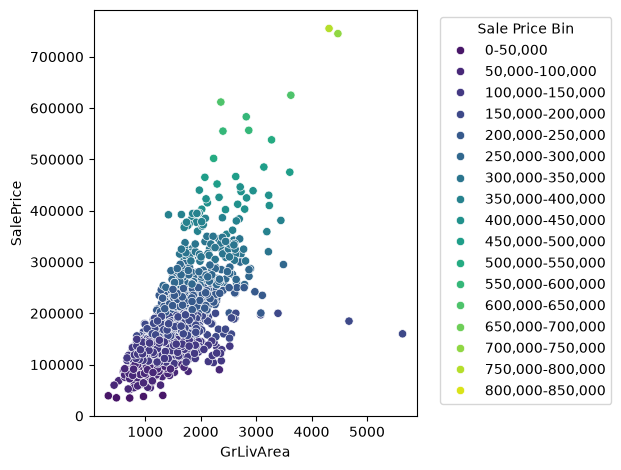

In [8]:
# make bin labels for housing prices every $50,000
sale_price_bins = [
    f'{i:,}-{i+50_000:,}'
    for i in range(0, 850_000, 50_000)
]

# create new column and map price to correct bin
train_data_df['SalePriceBin'] = pd.cut(
    train_data_df['SalePrice'],
    bins=list(range(0, 850001, 50000)),
    labels=sale_price_bins,
    include_lowest=True
)

# plot the living area comapred to price and use the pricing bins as hue
sns.scatterplot(
    data=train_data_df,
    x='GrLivArea',
    y='SalePrice',
    hue='SalePriceBin',
    palette='viridis'
)

plt.legend(title='Sale Price Bin', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

It appears that there is a positive correlation between the amount of living area and the price. There are a few outliers with a lot of living area but relatively cheap selling price.

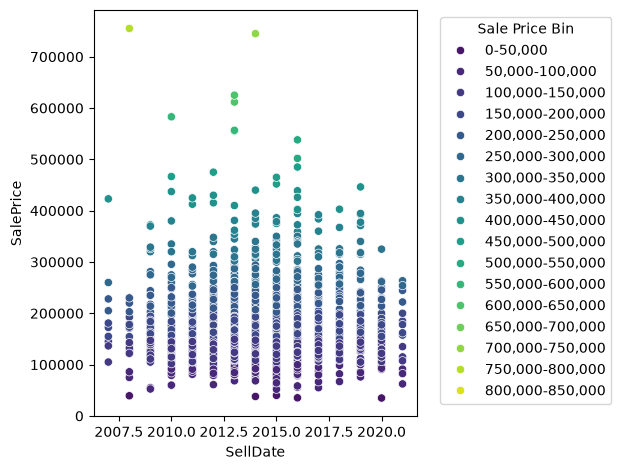

In [37]:
train_data_df['SellDate'] = train_data_df['MoSold'] + train_data_df['YrSold']

# plot the sell date comapred to price and use the pricing bins as hue
sns.scatterplot(
    data=train_data_df,
    x='SellDate',
    y='SalePrice',
    hue='SalePriceBin',
    palette='viridis'
)

plt.legend(title='Sale Price Bin', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

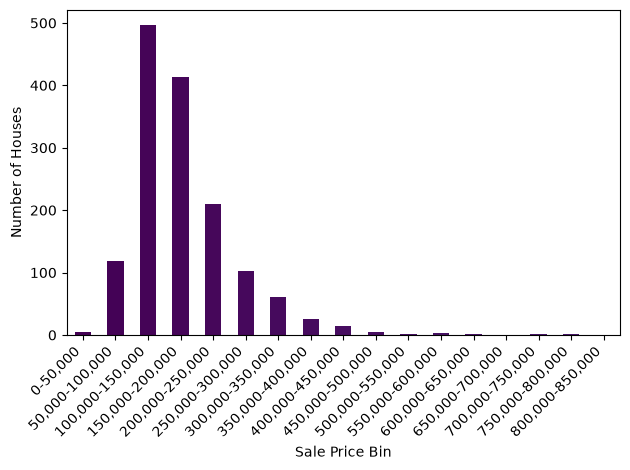

In [9]:
train_data_df['SalePriceBin'].value_counts(sort=False).plot(kind='bar', color=plt.cm.viridis(
    range(len(sale_price_bins))
))
plt.xticks(rotation=45, ha='right')
plt.xlabel('Sale Price Bin')
plt.ylabel('Number of Houses')
plt.tight_layout()
plt.show()

Most houses fell within 100,000 and 250,000.

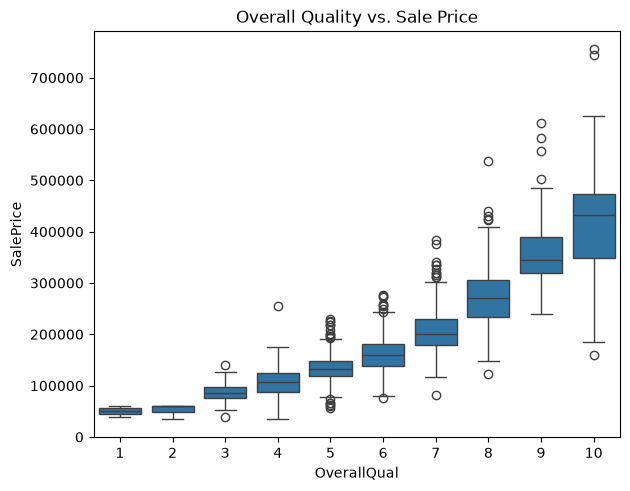

In [19]:


sns.boxplot(data=train_data_df, x='OverallQual', y='SalePrice')

plt.tight_layout()
plt.title("Overall Quality vs. Sale Price")
plt.show()

## Compare Sale Prices Across Categories

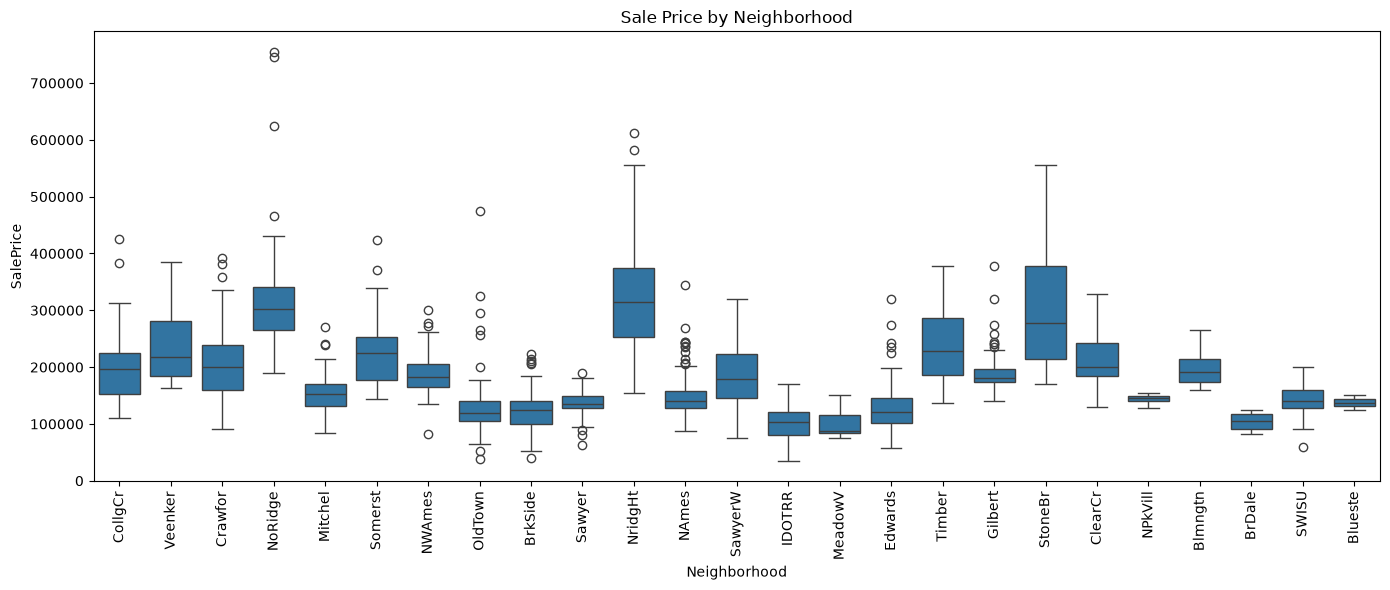

In [21]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=train_data_df, x='Neighborhood', y='SalePrice')
plt.xticks(rotation=90)
plt.title('Sale Price by Neighborhood')
plt.tight_layout()
plt.show()

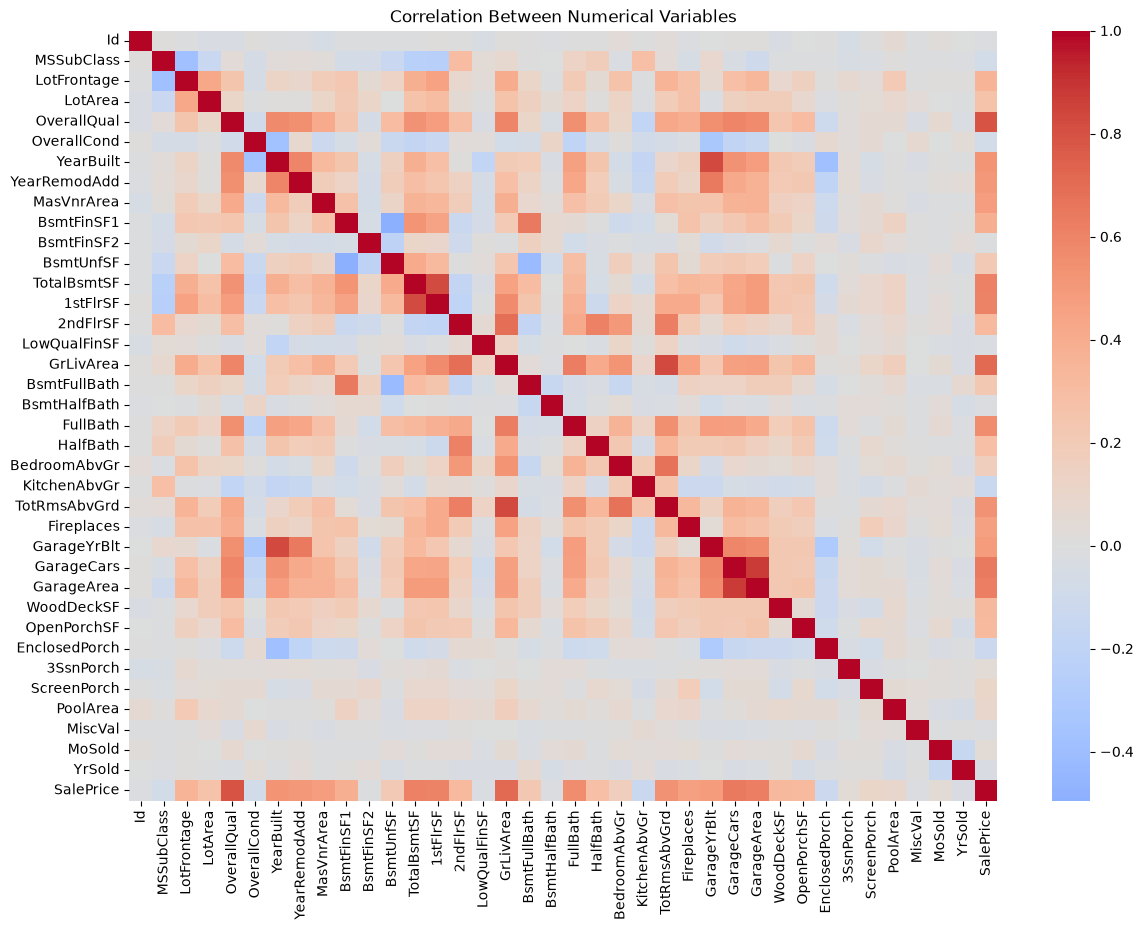

In [22]:
numeric_df = train_data_df.select_dtypes(include='number')

corr = numeric_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Between Numerical Variables')
plt.show()

## House Age and Renovations

In [24]:
train_data_df['HouseAgeAtSale'] = train_data_df['YrSold'] - train_data_df['YearBuilt']
train_data_df['YearsSinceRemodel'] = train_data_df['YrSold'] - train_data_df['YearRemodAdd']

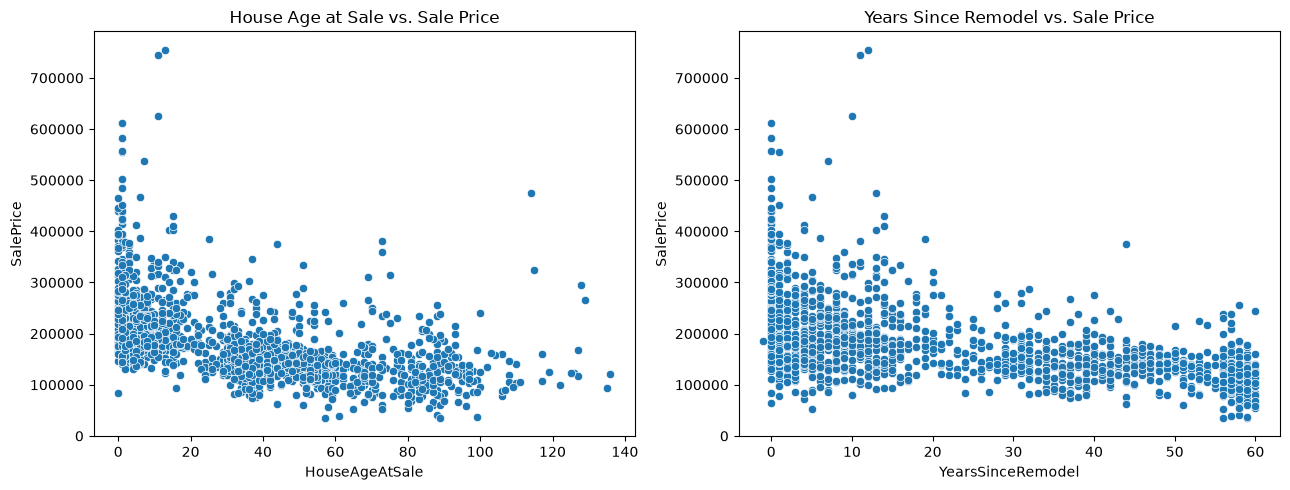

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=train_data_df, x='HouseAgeAtSale', y='SalePrice', ax=axes[0])
axes[0].set_title('House Age at Sale vs. Sale Price')

sns.scatterplot(data=train_data_df, x='YearsSinceRemodel', y='SalePrice', ax=axes[1])
axes[1].set_title('Years Since Remodel vs. Sale Price')

plt.tight_layout()
plt.show()

## Outliers

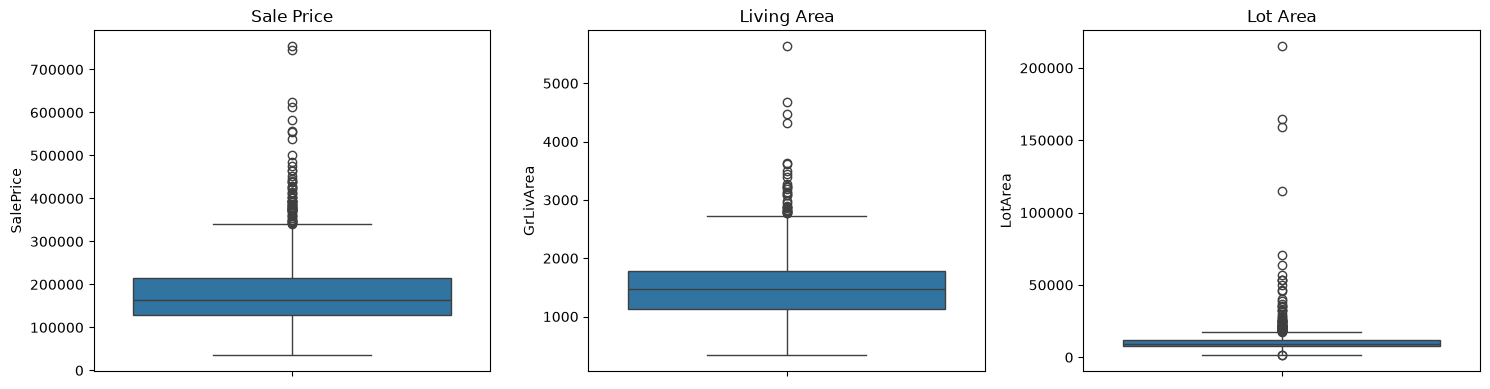

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=train_data_df['SalePrice'], ax=axes[0])
sns.boxplot(y=train_data_df['GrLivArea'], ax=axes[1])
sns.boxplot(y=train_data_df['LotArea'], ax=axes[2])

axes[0].set_title('Sale Price')
axes[1].set_title('Living Area')
axes[2].set_title('Lot Area')

plt.tight_layout()
plt.show()